# Is it really a core? Core-periphery detection vs. degree-preserving null models

## 0. Setup

### 0.1. Imports

In [1]:
# Standard library
import random
import time
from pathlib import Path

# Scientific stack
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Core-periphery detection (Kojaku's cpnet) and numba (used inside cpnet)
import cpnet
import numba

### 0.2. Global parameters and random seeds

In [2]:
# Random seeds
SEED = 5441  # master seed used everywhere unless stated otherwise


@numba.njit
def _seed_numba(seed):
    # numba keeps its own random state, so it has to be seeded from inside a jitted function
    np.random.seed(seed)


def seed_all(seed):
    """Seed Python, NumPy and numba (cpnet's BE and Rombach run in numba)."""
    random.seed(seed)
    np.random.seed(seed)
    _seed_numba(seed)


seed_all(SEED)

# Detection methods
N_RESTARTS = 10                            # random restarts per method (keep the best run)
ROMBACH_GRID = [0.1, 0.3, 0.5, 0.7, 0.9]   # alpha and beta values for the 5x5 Rombach grid

# Null model
SWAP_FACTOR = 10     # number of edge swaps = SWAP_FACTOR * number of edges
TRY_FACTOR = 1000    # max swap attempts  = TRY_FACTOR * number of edges (dense networks reject most swaps, so allow many attempts)
N_NULL_SYNTH = 100   # null networks per synthetic network
N_NULL_EMP = 100     # null networks for the empirical network

### 0.3. I/O helpers

In [3]:
# Folders for raw data, computed results (CSV) and figures (PDF)
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIG_DIR = PROJECT_DIR / "figures"
for d in (DATA_DIR, RESULTS_DIR, FIG_DIR):
    d.mkdir(exist_ok=True)


def save_csv(df, name):
    """Save a DataFrame to results/<name>.csv."""
    path = RESULTS_DIR / f"{name}.csv"
    df.to_csv(path, index=False)
    print(f"saved {path.relative_to(PROJECT_DIR)}")


def load_csv(name):
    """Load results/<name>.csv."""
    return pd.read_csv(RESULTS_DIR / f"{name}.csv")


def save_fig(fig, name):
    """Save a figure to figures/<name>.pdf (for Overleaf)."""
    path = FIG_DIR / f"{name}.pdf"
    fig.savefig(path, bbox_inches="tight")
    print(f"saved {path.relative_to(PROJECT_DIR)}")

## 1. Detection methods

### 1.0. Shared helpers
Adjacency matrix, pair correlation, top-$k$ core

In [4]:
def adjacency(G):
    """Dense 0/1 adjacency matrix (rows/columns follow list(G.nodes()))."""
    return nx.to_numpy_array(G, nodelist=list(G.nodes()), weight=None)


def dict_to_array(d, G):
    """Turn a {node: value} dict (cpnet output) into an array ordered like G.nodes()."""
    return np.array([d[n] for n in G.nodes()])


def pair_corr(A, D, mask=None):
    """Pearson correlation between A and an ideal pattern D,
    using each pair once (upper triangle, no diagonal).
    `mask` (optional) keeps only some pairs, e.g. to drop 'missing' pairs in BE Eq. 4."""
    iu = np.triu_indices(A.shape[0], k=1)
    a, d = A[iu], D[iu]
    if mask is not None:
        keep = mask[iu]
        a, d = a[keep], d[keep]
    if a.std() == 0 or d.std() == 0:  # correlation undefined (e.g. empty core)
        return np.nan
    return np.corrcoef(a, d)[0, 1]


def top_k_core(coreness, k):
    """Turn continuous coreness into a 0/1 core: the k nodes with the highest coreness."""
    x = np.zeros(len(coreness), dtype=int)
    x[np.argsort(-coreness)[:k]] = 1
    return x


def auc(score, planted):
    """Area under the ROC curve: probability that a random planted-core node gets a higher
    score than a random periphery node (ties count 1/2), via the Mann-Whitney U statistic.
    0.5 = chance, 1 = perfect. With a 0/1 score this equals balanced accuracy (TPR + TNR) / 2."""
    from scipy.stats import rankdata
    ranks = rankdata(score) # average ranks handle ties
    n1, n0 = planted.sum(), len(planted) - planted.sum()
    u = ranks[planted == 1].sum() - n1 * (n1 + 1) / 2
    return u / (n1 * n0)

### 1.1. `detect_be_eq2`
Borgatti & Everett's discrete, Eq. 2

In [5]:
def be_eq2_pattern(x):
    """BE Eq. 2 ideal pattern: delta_ij = 1 if i or j is in the core."""
    return np.maximum.outer(x, x)


def detect_be_eq2(G, seed=SEED):
    """Borgatti & Everett discrete model, Eq. 2 (cpnet.BE).
    Returns (x, rho): x[i] = 1 if node i is core, rho = corr(A, Eq. 2 pattern)."""
    seed_all(seed)
    alg = cpnet.BE(num_runs=N_RESTARTS)
    alg.detect(G)
    x = dict_to_array(alg.get_coreness(), G).astype(int)

    rho = pair_corr(adjacency(G), be_eq2_pattern(x))
    return x, rho

### 1.2. `detect_be_eq4`
Borgatti & Everett's discrete, Eq. 4

In [6]:
def _rho_eq4(m_cc, m_pp, n_cc, n_pp):
    """BE Eq. 4 correlation from counts (works on arrays too).
    Only core-core pairs (ideal = 1) and periphery-periphery pairs (ideal = 0) count;
    core-periphery pairs are 'missing'.
      m_cc, m_pp = edges inside core / inside periphery
      n_cc, n_pp = pairs inside core / inside periphery"""
    m_cc, m_pp, n_cc, n_pp = (np.asarray(v, dtype=float) for v in (m_cc, m_pp, n_cc, n_pp))
    n = n_cc + n_pp
    with np.errstate(divide="ignore", invalid="ignore"):
        pa = (m_cc + m_pp) / n        # edge density over the counted pairs
        pd_ = n_cc / n                # fraction of counted pairs that are core-core
        rho = (m_cc / n - pa * pd_) / np.sqrt(pa * (1 - pa) * pd_ * (1 - pd_))
    # Undefined cases (core or periphery with < 2 nodes, no edges, ...) are never chosen
    return np.where(np.isfinite(rho), rho, -np.inf)


def _pairs(k):
    """Number of node pairs among k nodes."""
    return k * (k - 1) / 2


def _greedy_eq4(A, x):
    """Greedy single-node flips from start partition x: repeatedly make the flip
    (core <-> periphery) that increases rho the most, until no flip helps."""
    N = len(x)
    deg = A.sum(axis=1)
    k_core = A @ x                    # number of core neighbours of each node
    m_cc = x @ A @ x / 2              # edges inside the core
    m_pp = (1 - x) @ A @ (1 - x) / 2  # edges inside the periphery
    rho = _rho_eq4(m_cc, m_pp, _pairs(x.sum()), _pairs(N - x.sum()))

    while True:
        nc = x.sum()
        to_core = x == 0  # True: node would move periphery -> core; False: core -> periphery
        # Counts after flipping each node (vectorised over all N candidate flips)
        new_m_cc = np.where(to_core, m_cc + k_core, m_cc - k_core)
        new_m_pp = np.where(to_core, m_pp - (deg - k_core), m_pp + (deg - k_core))
        new_nc = np.where(to_core, nc + 1, nc - 1)
        new_rho = _rho_eq4(new_m_cc, new_m_pp, _pairs(new_nc), _pairs(N - new_nc))

        i = np.argmax(new_rho)
        if new_rho[i] <= rho + 1e-12:  # no flip improves rho -> local optimum
            return x, rho

        # Apply the best flip and update the counts
        sign = 1 if to_core[i] else -1
        x[i] = 1 - x[i]
        m_cc, m_pp, rho = new_m_cc[i], new_m_pp[i], new_rho[i]
        k_core = k_core + sign * A[:, i]


def detect_be_eq4(G, seed=SEED, n_restarts=N_RESTARTS):
    """Borgatti & Everett discrete model, Eq. 4 (own code).
    Greedy flips from several random starts; keep the best.
    Returns (x, rho): x[i] = 1 if node i is core."""
    rng = np.random.default_rng(seed)
    A = adjacency(G)
    N = A.shape[0]
    best_x, best_rho = None, -np.inf
    for _ in range(n_restarts):
        # Random start: each node is core with probability q, q drawn between 0.1 and 0.5
        q = rng.uniform(0.1, 0.5)
        x0 = (rng.random(N) < q).astype(float)
        x, rho = _greedy_eq4(A, x0)
        if rho > best_rho:
            best_x, best_rho = x.copy(), rho
    return best_x.astype(int), float(best_rho)

### 1.3. `detect_minres`
MINRES continuous

In [7]:
def detect_minres(G, seed=SEED, tol=1e-10, max_iter=10_000):
    """Borgatti & Everett continuous model fitted by MINRES (own code).
    Finds coreness c minimising sum_{i != j} (A_ij - c_i c_j)^2.
    Uses the fixed-point equation c_i = sum_j A_ij c_j / sum_{j != i} c_j^2
    (Boyd et al. 2010), with a damped (geometric-mean) update for stability.
    Deterministic, so `seed` is unused (kept so all methods share one interface).
    Returns (c, rho): c = coreness, rho = corr(A, c c^T) over pairs."""
    A = adjacency(G)
    c = np.ones(A.shape[0])
    for _ in range(max_iter):
        target = (A @ c) / (np.sum(c**2) - c**2)  # fixed-point update
        c_new = np.sqrt(c * target)               # damped step
        if np.max(np.abs(c_new - c)) < tol:       # converged
            c = c_new
            break
        c = c_new
    rho = pair_corr(A, np.outer(c, c))
    return c, rho

### 1.4. `detect_rombach`
Rombach aggregate core score, $5\times5\; (\alpha, \beta)$ grid

$\alpha, \beta \in \{0.1,\, 0.3,\, 0.5,\, 0.7,\, 0.9\}$

In [8]:
def detect_rombach(G, seed=SEED, grid=ROMBACH_GRID):
    """Rombach et al. (2017) aggregate core score over an alpha x beta grid (cpnet.Rombach, 'ls').
    For each (alpha, beta): find coreness C maximising R = sum_ij A_ij C_i C_j.
    Aggregate: CS(i) = Z * sum C_i(alpha, beta) * R(alpha, beta), scaled so the top node = 1.
    Note: in cpnet, beta = fraction of PERIPHERY nodes (large beta -> small core).
    Returns (CS, R_max): R_max = largest R over the grid (score for the null test)."""
    CS = np.zeros(G.number_of_nodes())
    R_max = -np.inf
    for alpha in grid:
        for beta in grid:
            seed_all(seed)
            alg = cpnet.Rombach(num_runs=N_RESTARTS, alpha=alpha, beta=beta, algorithm="ls")
            alg.detect(G)
            C = dict_to_array(alg.get_coreness(), G)
            R = alg.Q_                  # core quality R for this (alpha, beta)
            CS += C * R                 # weight each coreness vector by its quality
            R_max = max(R_max, R)
    CS = CS / CS.max()                  # Z: scale so the top node has CS = 1
    return CS, float(R_max)

### 1.5. Sanity check on a toy planted network

In [9]:
# The four methods, used throughout the rest of the notebook
METHODS = {
    "BE Eq. 2": detect_be_eq2,
    "BE Eq. 4": detect_be_eq4,
    "MINRES": detect_minres,
    "Rombach": detect_rombach,
}
DISCRETE = {"BE Eq. 2", "BE Eq. 4"}  # methods that return a 0/1 core directly


def get_core(name, x, k):
    """0/1 core for any method: discrete methods give it directly,
    continuous ones (MINRES, Rombach) take their top-k nodes."""
    return x.astype(int) if name in DISCRETE else top_k_core(x, k)


# Toy planted core-periphery network: 20 core + 60 periphery nodes, with a clear core (dense core, medium core-periphery, sparse periphery)
toy_sizes = [20, 60]
toy_P = [[0.6, 0.2],
         [0.2, 0.03]]
G_toy = nx.stochastic_block_model(toy_sizes, toy_P, seed=SEED)
planted = np.array([G_toy.nodes[n]["block"] == 0 for n in G_toy.nodes()]).astype(int)
k_planted = planted.sum()
print(f"Toy network: {G_toy.number_of_nodes()} nodes, {G_toy.number_of_edges()} edges")

rows = []
for name, detect in METHODS.items():
    t0 = time.perf_counter()
    x, score = detect(G_toy)
    secs = time.perf_counter() - t0

    core = get_core(name, x, k_planted)
    # AUC of the method's output vs. the planted core (discrete methods: 0/1 labels -> balanced accuracy; continuous: coreness)
    rows.append({"method": name, "score": round(score, 3), "core size": int(core.sum()),
                 "AUC / bal. acc.": round(auc(x, planted), 3), "seconds": round(secs, 2)})

display(pd.DataFrame(rows))

# Cross-check: our rho for Eq. 2 should equal cpnet's own BE score
seed_all(SEED)
be = cpnet.BE(num_runs=N_RESTARTS)
be.detect(G_toy)
print("cpnet BE score:", round(be.Q_, 4), "| our Eq. 2 rho:", round(detect_be_eq2(G_toy)[1], 4))

# Cross-check: MINRES coreness should be close to the leading eigenvector of A
c, _ = detect_minres(G_toy)
v = np.abs(np.linalg.eigh(adjacency(G_toy))[1][:, -1])
print("corr(MINRES coreness, leading eigenvector):", round(np.corrcoef(c, v)[0, 1], 3))

Toy network: 80 nodes, 388 edges


,method,score,core size,AUC / bal. acc.,seconds
0,BE Eq. 2,0.337,17,0.925,0.01
1,BE Eq. 4,0.605,20,1.000,0.00
2,MINRES,0.472,20,1.000,0.00
3,Rombach,717.317,20,1.000,0.10


cpnet BE score: 0.337 | our Eq. 2 rho: 0.337
corr(MINRES coreness, leading eigenvector): 1.0


## 2. Null model

### 2.1. `rewire`
Degree-preserving edge swaps

In [10]:
def rewire(G, seed):
    """Degree-preserving null network: repeated double edge swaps
    (a-b, c-d  ->  a-d, c-b). Every node keeps its exact degree and the graph stays simple."""
    H = G.copy()
    L = H.number_of_edges()
    nx.double_edge_swap(H, nswap=SWAP_FACTOR * L, max_tries=TRY_FACTOR * L, seed=seed)
    return H

### 2.2. `null_test`
Real score vs. null scores, z-score, p-value

In [11]:
def null_test(G, methods, n_null, seed=SEED, n_jobs=1):
    """Compare each method's optimised score on G with its optimised scores
    on n_null degree-preserving rewirings of G (the method is re-run from scratch on each).
    The same rewired networks are reused for every method in `methods` ({name: function}).
    n_jobs: parallel workers for the null networks (1 = one after another; -1 = all CPU cores).

    Returns {name: {"real", "null" (array), "z", "p"}} where
      z = (real - mean(null)) / std(null)
      p = (k + 1) / (n_null + 1), k = number of null scores >= real (one-sided)."""
    # One rewiring seed per null network, all derived from `seed`
    null_seeds = np.random.default_rng(seed).integers(0, 2**31 - 1, size=n_null)

    real = {name: f(G, seed)[1] for name, f in methods.items()}

    def _scores(s):
        """Rewire G with seed s and return every method's optimised score on the null network."""
        H = rewire(G, int(s))
        return {name: f(H, seed)[1] for name, f in methods.items()}

    if n_jobs == 1:
        per_null = [_scores(s) for s in null_seeds]
    else:
        from joblib import Parallel, delayed
        per_null = Parallel(n_jobs=n_jobs)(delayed(_scores)(s) for s in null_seeds)
    null = {name: [r[name] for r in per_null] for name in methods}

    out = {}
    for name in methods:
        scores = np.array(null[name], dtype=float)
        sd = scores.std(ddof=1)
        out[name] = {
            "real": real[name],
            "null": scores,
            "z": (real[name] - scores.mean()) / sd if sd > 0 else np.nan,
            "p": (np.sum(scores >= real[name]) + 1) / (n_null + 1),
        }
    return out


# Quick check on the toy network (10 null networks only)
toy_test = null_test(G_toy, METHODS, n_null=10)
display(pd.DataFrame({name: {"real": r["real"], "null mean": r["null"].mean(), "z": r["z"], "p": r["p"]}
                      for name, r in toy_test.items()}).T.round(3))

,real,null mean,z,p
BE Eq. 2,0.337,0.329,1.169,0.273
BE Eq. 4,0.605,0.614,-1.725,1.000
MINRES,0.472,0.480,-0.974,0.818
Rombach,717.317,714.136,3.856,0.091


### 2.3. Timing check

In [12]:
# Time one rewiring and one run of each method on a sparse and a dense 2-block SBM (the same sizes as section 3), to choose how many null networks we can afford
timing_rows = []
for p12 in (0.15, 1.0):
    G_t = nx.stochastic_block_model([30, 70], [[0.5, p12], [p12, 0.05]], seed=SEED)
    t0 = time.perf_counter()
    H_t = rewire(G_t, SEED)
    row = {"p12": p12, "edges": G_t.number_of_edges(), "rewire": time.perf_counter() - t0}
    # How different is the null network? (share of original edges that were swapped away)
    row["edges changed"] = 1 - len(set(map(frozenset, G_t.edges())) & set(map(frozenset, H_t.edges()))) / row["edges"]
    for name, f in METHODS.items():
        t0 = time.perf_counter()
        f(H_t)
        row[name] = time.perf_counter() - t0
    timing_rows.append(row)

timing = pd.DataFrame(timing_rows).set_index("p12")
display(timing.round(3))

# Cost of one null test = n_null x (rewire + all methods)
per_null = timing.drop(columns=["edges", "edges changed"]).sum(axis=1)
print("Seconds per null test with N_NULL_SYNTH =", N_NULL_SYNTH, ":", (per_null * N_NULL_SYNTH).round(0).to_dict())

,edges,rewire,edges changed,BE Eq. 2,BE Eq. 4,MINRES,Rombach
p12,,,,,,,
0.15,630,0.024,0.74,0.009,0.005,0.001,0.171
1.00,2422,0.627,0.22,0.002,0.006,0.001,0.383


Seconds per null test with N_NULL_SYNTH = 100 : {0.15: 21.0, 1.0: 102.0}


## 3. Synthetic networks

### 3.1. `make_sbm`
2-block SBMs (30 core, 70 periphery) with $P_{11} = 0.5$ and $P_{22} = 0.05$ fixed and $P_{12}$ swept from 0 to 1 (assortative → core–periphery → disassortative), plus the degree-explained point $P_{12} = \sqrt{P_{11}P_{22}}$ and an ER control

In [13]:
# Synthetic design
# Two blocks: block 0 = planted core (30 nodes), block 1 = periphery (70 nodes).
# P11 (core-core) and P22 (periphery-periphery) are fixed; P12 (core-periphery) is swept from 0 to 1.
SIZES = [30, 70]
P11, P22 = 0.5, 0.05
P12_DEG = np.sqrt(P11 * P22)                     # P12^2 = P11*P22: block structure fully explained by degrees
# 0, 0.05, ..., 1, plus the exact degree-explained point (here ~0.158, not on the 0.05 grid)
P12_GRID = np.unique(np.append(np.round(np.linspace(0, 1, 21), 2), P12_DEG))

RECOVERY_SEEDS = [SEED + i for i in range(10)]  # networks per P12 for core recovery
NULL_SEEDS = RECOVERY_SEEDS[:5]                  # networks per P12 for the (slower) null tests
ER_SEEDS = [SEED + i for i in range(100)]        # ER control networks (cheap, so more of them)


def make_sbm(p12, seed, sizes=SIZES, p11=P11, p22=P22):
    """2-block SBM. Returns (G, planted) with planted[i] = 1 if node i is in the planted core."""
    P = [[p11, p12],
         [p12, p22]]
    G = nx.stochastic_block_model(sizes, P, seed=seed)
    planted = np.array([G.nodes[n]["block"] == 0 for n in G.nodes()]).astype(int)
    return G, planted


def make_er(seed, sizes=SIZES):
    """ER control (false-positive check): same number of nodes and the same expected
    number of edges as the degree-explained SBM (P12 = P12_DEG)."""
    n_core, n_per = sizes
    N = n_core + n_per
    exp_edges = (P11 * n_core * (n_core - 1) / 2 + P12_DEG * n_core * n_per
                 + P22 * n_per * (n_per - 1) / 2)
    return nx.gnp_random_graph(N, exp_edges / (N * (N - 1) / 2), seed=seed)


def block_structure(p12, p11=P11, p22=P22):
    """Two-group classification (Liu et al. 2023; Zhang et al. 2015), with P11 >= P22."""
    if p12 < p22:
        return "assortative"
    if p12 == p22:
        return "boundary (P12 = P22)"
    if p12 < p11:
        return "core-periphery"
    if p12 == p11:
        return "boundary (P12 = P11)"
    return "disassortative"


def beyond_degrees(p12, p11=P11, p22=P22):
    """What remains after degrees are accounted for (Kojaku & Masuda 2018):
    sign of P11*P22 - P12^2."""
    d = p11 * p22 - p12**2
    if np.isclose(d, 0):
        return "nothing (degree-explained)"
    return "assortative" if d > 0 else "disassortative"


# Check every case before running anything
cases = pd.DataFrame({"P12": P12_GRID})
cases["structure"] = cases["P12"].apply(block_structure)
cases["beyond degrees"] = cases["P12"].apply(beyond_degrees)
cases["mean edges"] = [np.mean([make_sbm(p, s)[0].number_of_edges() for s in NULL_SEEDS]) for p in P12_GRID]
print(f"P11 = {P11}, P22 = {P22}, degree-explained point P12 = sqrt(P11*P22) = {P12_DEG:.2f}")
print(f"ER control: {make_er(SEED).number_of_edges()} edges")
display(cases)

P11 = 0.5, P22 = 0.05, degree-explained point P12 = sqrt(P11*P22) = 0.16
ER control: 653 edges


,P12,structure,beyond degrees,mean edges
0,0.000000,assortative,assortative,335.2
1,0.050000,boundary (P12 = P22),assortative,435.6
2,0.100000,core-periphery,assortative,538.8
3,0.150000,core-periphery,assortative,640.6
4,0.158114,core-periphery,nothing (degree-explained),654.8
5,0.200000,core-periphery,disassortative,743.6
6,0.250000,core-periphery,disassortative,847.2
7,0.300000,core-periphery,disassortative,954.8
8,0.350000,core-periphery,disassortative,1057.4
9,0.400000,core-periphery,disassortative,1160.4


### 3.2. Core recovery
Run methods, compare with planted core

In [14]:
# For each P12 and each seed: run all methods.
# Split accuracy (AUC vs. the planted core) is only computed for core-periphery networks
# (P22 < P12 < P11); elsewhere the planted "core" is not a core, so auc = NaN.
# Discrete methods (0/1 labels) -> AUC = balanced accuracy; continuous methods -> AUC of the coreness.
# Cores for the agreement analysis (3.4): continuous methods use their top-k nodes, k = planted core size (30).
k_core = SIZES[0]
recovery_rows = []
synth_cores = {}  # (P12, seed, method) -> 0/1 core, reused in 3.4
node_rows = []    # node-level coreness of every method, reused in 3.4

for p12 in P12_GRID:
    for seed in RECOVERY_SEEDS:
        G, planted = make_sbm(p12, seed)
        for name, f in METHODS.items():
            x, score = f(G)
            core = get_core(name, x, k_core)
            synth_cores[(p12, seed, name)] = core
            # Coreness scaled so the top node = 1 (discrete methods stay 0/1)
            scaled = x / x.max() if x.max() > 0 else x
            node_rows += [{"p12": p12, "seed": seed, "method": name, "node": n, "planted": planted[i],
                           "degree": G.degree(n), "coreness": scaled[i]}
                          for i, n in enumerate(G.nodes())]
            recovery_rows.append({
                "p12": p12, "seed": seed, "method": name, "score": score,
                "core_size": int(core.sum()),
                "auc": auc(x, planted) if block_structure(p12) == "core-periphery" else np.nan,  # 0.5 = chance, 1 = perfect
            })

recovery = pd.DataFrame(recovery_rows)
print("Split accuracy (AUC / balanced accuracy) on core-periphery networks:")
display(recovery.dropna(subset=["auc"]).groupby(["p12", "method"])["auc"].mean().unstack().round(3))

Split accuracy (AUC / balanced accuracy) on core-periphery networks:


method,BE Eq. 2,BE Eq. 4,MINRES,Rombach
p12,,,,
0.100000,0.803,0.985,1.000,1.000
0.150000,0.881,0.995,1.000,1.000
0.158114,0.867,0.997,1.000,1.000
0.200000,0.923,0.994,1.000,0.999
0.250000,0.958,0.989,1.000,0.999
0.300000,0.975,0.975,0.999,0.997
0.350000,0.988,0.966,1.000,0.997
0.400000,0.983,0.955,0.999,0.994
0.450000,0.983,0.950,1.000,0.994


### 3.3. Null tests
Run `null_test` on 5 networks per $P_{12}$ and 100 ER control networks, 100 null networks each; cached in `results/`

In [15]:
from joblib import Parallel, delayed

# Null tests are the slow part, so they are cached in results/ and only missing tests are run.
# A cached test is reused only if it was made with the current P11, P22 and N_NULL_SYNTH.
# Set RECOMPUTE = True to ignore the cache and run everything again.
RECOMPUTE = False
null_file = RESULTS_DIR / "synthetic_null_summary.csv"


def _null_one(case, p12, seed):
    """Null test for one synthetic network (runs in a separate worker process)."""
    G = make_er(seed) if case == "ER" else make_sbm(p12, seed)[0]
    res = null_test(G, METHODS, n_null=N_NULL_SYNTH, seed=seed)
    summary = [{"case": case, "p11": P11, "p22": P22, "p12": p12, "seed": seed, "method": name,
                "real": r["real"], "null_mean": r["null"].mean(), "null_std": r["null"].std(ddof=1),
                "z": r["z"], "p": r["p"]} for name, r in res.items()]
    raw = [{"case": case, "p12": p12, "seed": seed, "method": name, "null_score": s}
           for name, r in res.items() for s in r["null"]]
    return summary, raw


def _key(case, p12, seed):
    """Identifier of one tested network (ER networks have no P12)."""
    return (case, -1.0 if pd.isna(p12) else round(float(p12), 6), int(seed))


def _keys(df):
    return [_key(c, p, s) for c, p, s in zip(df["case"], df["p12"], df["seed"])]


def _load_cache():
    """Cached tests that are still valid for the current settings (two empty frames if none)."""
    if RECOMPUTE or not null_file.exists():
        return pd.DataFrame(), pd.DataFrame()
    summ, raw = load_csv("synthetic_null_summary"), load_csv("synthetic_null_raw")
    if "p11" not in summ:
        return pd.DataFrame(), pd.DataFrame()
    summ = summ[np.isclose(summ["p11"], P11) & np.isclose(summ["p22"], P22)]
    # A network counts as done only if every method has exactly N_NULL_SYNTH null scores
    counts = raw.groupby(["case", "p12", "seed", "method"], dropna=False).size().reset_index(name="n")
    complete = counts[counts["n"] == N_NULL_SYNTH].groupby(["case", "p12", "seed"], dropna=False).size()
    ok = {_key(*k) for k, n in complete.items() if n == len(METHODS)} & set(_keys(summ))
    return (summ[[k in ok for k in _keys(summ)]], raw[[k in ok for k in _keys(raw)]])


# All networks to test: the SBM sweep plus the ER control (p12 = NaN for ER)
jobs = [("SBM", p12, s) for p12 in P12_GRID for s in NULL_SEEDS] + [("ER", np.nan, s) for s in ER_SEEDS]
cached_summ, cached_raw = _load_cache()
done = set(_keys(cached_summ)) if len(cached_summ) else set()
todo = [job for job in jobs if _key(*job) not in done]
print(f"{len(jobs) - len(todo)} null tests loaded from cache, {len(todo)} to run")

summ_parts, raw_parts = [cached_summ], [cached_raw]
if todo:
    t0 = time.perf_counter()
    out = Parallel(n_jobs=-1, verbose=5)(delayed(_null_one)(*job) for job in todo)  # one job per network
    print(f"{len(todo)} null tests in {(time.perf_counter() - t0) / 60:.1f} min")
    summ_parts.append(pd.DataFrame([row for summary, _ in out for row in summary]))
    raw_parts.append(pd.DataFrame([row for _, raw in out for row in raw]))

# Combine, keeping only the networks in the current design (drops tests from older grids/seeds)
wanted = {_key(*job) for job in jobs}
synth_null = pd.concat([d for d in summ_parts if len(d)], ignore_index=True)
synth_null = synth_null[[k in wanted for k in _keys(synth_null)]].reset_index(drop=True)
synth_null_raw = pd.concat([d for d in raw_parts if len(d)], ignore_index=True)
synth_null_raw = synth_null_raw[[k in wanted for k in _keys(synth_null_raw)]].reset_index(drop=True)

synth_null["significant"] = synth_null["p"] < 0.05
print(f"ER control ({len(ER_SEEDS)} networks): false-positive rate should be close to 5%")
er_summary = synth_null[synth_null["case"] == "ER"].groupby("method").agg(
    networks=("p", "size"), false_positive_pct=("significant", "mean"), mean_z=("z", "mean"))
er_summary["false_positive_pct"] = (100 * er_summary["false_positive_pct"]).round(1)
display(er_summary.round(3))
print("Share of SBM networks significant at p < 0.05:")
display(synth_null[synth_null["case"] == "SBM"].groupby(["p12", "method"])["significant"].mean().unstack())

210 null tests loaded from cache, 0 to run
ER control (100 networks): false-positive rate should be close to 5%


,networks,false_positive_pct,mean_z
method,,,
BE Eq. 2,100,9.0,0.160
BE Eq. 4,100,5.0,0.139
MINRES,100,9.0,0.084
Rombach,100,3.0,-0.051


Share of SBM networks significant at p < 0.05:


method,BE Eq. 2,BE Eq. 4,MINRES,Rombach
p12,,,,
0.000000,0.0,1.0,1.0,0.4
0.050000,0.0,1.0,1.0,0.0
0.100000,0.0,1.0,1.0,0.0
0.150000,0.0,0.8,0.6,0.0
0.158114,0.0,0.8,0.8,0.0
0.200000,0.0,0.0,0.0,0.0
0.250000,1.0,0.0,0.0,0.0
0.300000,1.0,0.0,0.0,0.0
0.350000,1.0,0.0,0.0,0.0


### 3.4. Method agreement
Overlap between methods' cores

In [16]:
from itertools import combinations


def jaccard(a, b):
    """Overlap of two 0/1 core vectors: |A and B| / |A or B|."""
    union = np.sum((a + b) > 0)
    return np.sum(a * b) / union if union > 0 else np.nan


# Node-level coreness of every method (plotted in 5.3)
synth_nodes = pd.DataFrame(node_rows)

# Pairwise Jaccard similarity between the methods' cores (from 3.2), per P12 and seed
agree_rows = []
for p12 in P12_GRID:
    for seed in RECOVERY_SEEDS:
        for m1, m2 in combinations(METHODS, 2):
            agree_rows.append({"p12": p12, "seed": seed, "pair": f"{m1} vs {m2}",
                               "jaccard": jaccard(synth_cores[(p12, seed, m1)], synth_cores[(p12, seed, m2)])})

synth_agree = pd.DataFrame(agree_rows)
display(synth_agree.groupby(["p12", "pair"])["jaccard"].mean().unstack().round(2))

pair,BE Eq. 2 vs BE Eq. 4,BE Eq. 2 vs MINRES,BE Eq. 2 vs Rombach,BE Eq. 4 vs MINRES,BE Eq. 4 vs Rombach,MINRES vs Rombach
p12,,,,,,
0.000000,0.48,0.42,0.42,0.84,0.84,1.00
0.050000,0.57,0.54,0.54,0.93,0.93,1.00
0.100000,0.62,0.61,0.60,0.97,0.97,0.99
0.150000,0.76,0.75,0.76,0.98,0.98,0.98
0.158114,0.73,0.73,0.73,0.99,0.99,1.00
0.200000,0.83,0.83,0.82,0.97,0.97,0.97
0.250000,0.87,0.91,0.87,0.95,0.93,0.94
0.300000,0.85,0.93,0.87,0.90,0.87,0.94
0.350000,0.84,0.97,0.87,0.87,0.85,0.89


### 3.5. Save results

In [17]:
save_csv(cases, "synthetic_cases")
save_csv(recovery, "synthetic_recovery")
save_csv(synth_null.drop(columns="significant"), "synthetic_null_summary")
save_csv(synth_null_raw, "synthetic_null_raw")
save_csv(synth_agree, "synthetic_agreement")
save_csv(synth_nodes, "synthetic_coreness")

saved results/synthetic_cases.csv
saved results/synthetic_recovery.csv
saved results/synthetic_null_summary.csv


saved results/synthetic_null_raw.csv
saved results/synthetic_agreement.csv


saved results/synthetic_coreness.csv


## 4. Empirical network

### Data sources
- **Network:** OpenFlights routes and airports, via Netzschleuder (`networks.skewed.de/net/openflights`, same data as graph-tool's `gt.collection.ns["openflights"]`); original data from https://openflights.org/data.html. The route data dates from **June 2014** (last OpenFlights route update), so it does not reflect 2025 services.
- **Metadata:** FAA *Passenger Boarding (Enplanement) Data*, calendar year **2025** (`arp-cy2025-commercial-service-enplanements.xlsx`), from https://www.faa.gov/airports/planning_capacity/passenger_allcargo_stats/passenger, downloaded on **12 November 2026**.
- The two sources are 11 years apart, so some airports have gained or lost service in between (e.g. Branson, Cincinnati Lunken); hub categories are used as external labels, not ground truth.

### 4.1. Load and preprocess data
US domestic airport network from OpenFlights (Netzschleuder), undirected and unweighted, largest connected component

In [18]:
import urllib.request
import zipfile

# ---- Data source ----
# OpenFlights network from Netzschleuder: the same data as graph-tool's gt.collection.ns["openflights"],
# downloaded as CSV so graph-tool is not needed. Original data: https://openflights.org/data.html
OPENFLIGHTS_URL = "https://networks.skewed.de/net/openflights/files/openflights.csv.zip"
OF_DIR = DATA_DIR / "openflights"


def download_openflights():
    """Download and unzip the Netzschleuder CSV files (skipped if already in data/openflights/)."""
    OF_DIR.mkdir(exist_ok=True)
    zip_path = OF_DIR / "openflights.csv.zip"
    if not zip_path.exists():
        urllib.request.urlretrieve(OPENFLIGHTS_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(OF_DIR, members=["nodes.csv", "edges.csv"])


def read_ns_csv(path):
    """Read a Netzschleuder CSV file (its header line starts with '# ')."""
    df = pd.read_csv(path)
    df.columns = [c.strip().lstrip("#").strip() for c in df.columns]
    return df


download_openflights()
of_nodes = read_ns_csv(OF_DIR / "nodes.csv")   # one row per airport (worldwide)
of_edges = read_ns_csv(OF_DIR / "edges.csv")   # one row per directed route per airline

# ---- Preprocessing ----
# 1. Keep US airports only, and routes between two US airports (domestic routes)
us_airports = of_nodes[of_nodes["country"] == "United States"].set_index("index")
assert us_airports["IATA/FAA"].is_unique, "IATA codes are used as node labels, so they must be unique"
us_routes = of_edges[of_edges["source"].isin(us_airports.index) & of_edges["target"].isin(us_airports.index)]

# 2. Undirected and unweighted: one edge per airport pair, ignoring direction, airline and number of routes
G_us = nx.Graph()
G_us.add_edges_from(zip(us_routes["source"], us_routes["target"]))
G_us.remove_edges_from(nx.selfloop_edges(G_us))

# 3. Keep the largest connected component
components = sorted(nx.connected_components(G_us), key=len, reverse=True)
G_air = G_us.subgraph(components[0]).copy()

# Label nodes by IATA code and keep the airport name and city as attributes
G_air = nx.relabel_nodes(G_air, us_airports["IATA/FAA"].to_dict())
info = us_airports.set_index("IATA/FAA")
nx.set_node_attributes(G_air, info["name"].to_dict(), "name")
nx.set_node_attributes(G_air, info["city"].to_dict(), "city")

# Summary of each preprocessing step
steps = pd.DataFrame([
    {"step": "all airports / directed routes (worldwide)", "nodes": len(of_nodes), "edges": len(of_edges)},
    {"step": "US airports / US-US routes", "nodes": len(us_airports), "edges": len(us_routes)},
    {"step": "undirected, unweighted, no self-loops", "nodes": G_us.number_of_nodes(), "edges": G_us.number_of_edges()},
    {"step": "largest connected component", "nodes": G_air.number_of_nodes(), "edges": G_air.number_of_edges()},
])
display(steps)
dropped = [sorted(us_airports.loc[list(c), "IATA/FAA"]) for c in components[1:]]
print("Dropped components:", dropped)

deg = pd.Series(dict(G_air.degree()), name="degree").sort_values(ascending=False)
print(f"Density {nx.density(G_air):.4f}, mean degree {deg.mean():.1f}, median degree {deg.median():.0f}, max degree {deg.max()}")
print("Top 10 airports by degree:")
display(deg.head(10).to_frame().assign(city=lambda d: [G_air.nodes[a]["city"] for a in d.index]))

# Save the processed network (edge list) for the report's appendix / reproducibility
nx.write_edgelist(G_air, DATA_DIR / "us_airports_edgelist.txt", data=False)

,step,nodes,edges
0,all airports / directed routes (worldwide),3214,66771
1,US airports / US-US routes,549,10518
2,"undirected, unweighted, no self-loops",549,2787
3,largest connected component,541,2780


Dropped components: [['BFI', 'CLM', 'ESD', 'FRD'], ['AKB', 'DUT', 'IKO', 'KQA']]
Density 0.0190, mean degree 10.3, median degree 3, max degree 153
Top 10 airports by degree:


,degree,city
ATL,153,Atlanta
DEN,149,Denver
ORD,149,Chicago
DFW,138,Dallas-Fort Worth
MSP,117,Minneapolis
DTW,114,Detroit
LAS,113,Las Vegas
CLT,110,Charlotte
IAH,101,Houston
PHL,88,Philadelphia


### 4.2. Load and match metadata
FAA CY2025 enplanements: hub category (L/M/S/N) attached to each airport

In [19]:
import warnings

# FAA hub categories (metadata)
# FAA "Passenger Boarding (Enplanement) Data", calendar year 2025: data/arp-cy2025-commercial-service-enplanements.xlsx
# Hub: L = large, M = medium, S = small, N = nonhub (all primary airports);
# nonprimary commercial-service airports have no hub category.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # openpyxl warns about the sheet's page header; harmless
    faa = pd.read_excel(DATA_DIR / "arp-cy2025-commercial-service-enplanements.xlsx")
faa.columns = [str(c).strip() for c in faa.columns]
faa = faa[faa["ST"].notna()].copy()            # drop the summary rows at the bottom of the sheet
faa["Locid"] = faa["Locid"].astype(str).str.strip()
faa_by_id = faa.set_index("Locid")

# Match network nodes (IATA codes) to FAA location ids
# 1. IATA code = FAA id (true for most US airports)
# 2. ICAO code "K" + FAA id (contiguous US). Not used for Alaska/Hawaii ("P..." codes),
#    where dropping the first letter gives wrong ids (e.g. Tatalina PATL -> "ATL" = Atlanta).
# 3. Manual: Palm Beach International (PBI) was renamed in 2025 and is listed under DJT.
MANUAL_IDS = {"PBI": "DJT"}


def faa_id(iata):
    """FAA location id for a network node, or None if the airport is not in the FAA list."""
    if iata in MANUAL_IDS:
        return MANUAL_IDS[iata]
    if iata in faa_by_id.index:
        return iata
    icao = str(info.loc[iata, "ICAO"]).strip()
    if len(icao) == 4 and icao.startswith("K") and icao[1:] in faa_by_id.index:
        return icao[1:]
    return None


def hub_label(fid):
    """Hub category: L/M/S/N, 'nonprimary' (in the FAA list but no hub category),
    or 'unlisted' (not in the FAA list, i.e. fewer than 2,500 boardings or no match)."""
    if pd.isna(fid):  # no match (pandas stores a missing id as NaN)
        return "unlisted"
    hub = faa_by_id.loc[fid, "Hub"]
    return hub if isinstance(hub, str) else "nonprimary"


match = pd.DataFrame({"iata": list(G_air.nodes())})
match["faa_id"] = match["iata"].map(faa_id)
match["matched_by"] = np.select(
    [match["iata"].isin(MANUAL_IDS), match["faa_id"] == match["iata"], match["faa_id"].notna()],
    ["manual", "IATA", "ICAO"], default="none")
match["hub"] = match["faa_id"].map(hub_label)
match["degree"] = match["iata"].map(dict(G_air.degree()))
match["name"] = match["iata"].map(nx.get_node_attributes(G_air, "name"))
nx.set_node_attributes(G_air, match.set_index("iata")["hub"].to_dict(), "hub")

# Check: does every node have a hub label?
print("How nodes were matched:", match["matched_by"].value_counts().to_dict())
print("Hub labels:", match["hub"].value_counts().reindex(["L", "M", "S", "N", "nonprimary", "unlisted"]).to_dict())
print(f"Nodes with a hub category (L/M/S/N): {match['hub'].isin(list('LMSN')).sum()} of {len(match)}")

print("\nMatches made through ICAO or manually (check the names agree):")
display(match[match["matched_by"].isin(["ICAO", "manual"])]
        .assign(faa_name=lambda d: d["faa_id"].map(faa_by_id["Airport Name"]))[["iata", "faa_id", "name", "faa_name", "hub"]])

print("Unlisted nodes (no FAA match), highest degree first:")
display(match[match["hub"] == "unlisted"].sort_values("degree", ascending=False)[["iata", "name", "degree"]].head(15))

# Large and medium FAA hubs that are not in the network (e.g. outside the 50 states)
in_net = set(match["faa_id"].dropna())
missing = faa[faa["Hub"].isin(["L", "M"]) & ~faa["Locid"].isin(in_net)]
print("FAA large/medium hubs not in the network:")
display(missing[["Locid", "ST", "City", "Airport Name", "Hub"]])

How nodes were matched: {'IATA': 428, 'none': 105, 'ICAO': 7, 'manual': 1}
Hub labels: {'L': 30, 'M': 34, 'S': 77, 'N': 219, 'nonprimary': 76, 'unlisted': 105}
Nodes with a hub category (L/M/S/N): 360 of 541

Matches made through ICAO or manually (check the names agree):


,iata,faa_id,name,faa_name,hub
31,AZA,IWA,Phoenix-Mesa-Gateway Airport,Mesa Gateway,S
91,PBI,DJT,Palm Beach International Airport,President Donald J Trump International,M
144,YUM,NYL,Yuma MCAS/Yuma International Airport,Yuma MCAS/Yuma International,N
176,CLD,CRQ,Mc Clellan-Palomar Airport,McClellan-Palomar,N
238,HHH,HXD,Hilton Head Airport,Hilton Head,N
268,FCA,GPI,Glacier Park International Airport,Glacier Park International,S
370,MQT,SAW,Sawyer International Airport,Marquette Sawyer Regional,N
372,SCE,UNV,University Park Airport,State College Regional,N


Unlisted nodes (no FAA match), highest degree first:


,iata,name,degree
460,HSL,Huslia Airport,5
532,KYU,Koyukuk Airport,4
338,WAA,Wales Airport,4
340,KKA,Koyuk Alfred Adams Airport,4
218,BKG,Branson Airport,4
423,SHG,Shungnak Airport,3
461,KAL,Kaltag Airport,3
324,EMK,Emmonak Airport,3
329,ELI,Elim Airport,3
311,KWN,Quinhagak Airport,3


FAA large/medium hubs not in the network:


,Locid,ST,City,Airport Name,Hub
38,SJU,PR,San Juan,Luis Munoz Marin International,M


### 4.3. Run detection methods

In [20]:
# Run every method on the airport network (same settings as in the synthetic part)
emp_rows, emp_x = [], {}
for name, f in METHODS.items():
    t0 = time.perf_counter()
    x, score = f(G_air)
    emp_x[name] = x
    emp_rows.append({"method": name, "score": score,
                     "core size": int(x.sum()) if name in DISCRETE else np.nan,
                     "seconds": time.perf_counter() - t0})
emp_methods = pd.DataFrame(emp_rows)
display(emp_methods.round(3))

# Node-level table: hub label, degree and every method's coreness (scaled so the top node = 1;
# discrete methods stay 0/1)
emp_nodes = pd.DataFrame({"iata": list(G_air.nodes())})
emp_nodes["hub"] = emp_nodes["iata"].map(nx.get_node_attributes(G_air, "hub"))
emp_nodes["degree"] = emp_nodes["iata"].map(dict(G_air.degree()))
emp_nodes["latitude"] = emp_nodes["iata"].map(info["latitude"])    # for the map in section 5
emp_nodes["longitude"] = emp_nodes["iata"].map(info["longitude"])
for name, x in emp_x.items():
    emp_nodes[name] = x / x.max()

# Who is in the core? Discrete methods: their core (by degree); continuous: their top 15 nodes
for name in METHODS:
    if name in DISCRETE:
        top = emp_nodes[emp_nodes[name] == 1].sort_values("degree", ascending=False)
        print(f"{name} core ({len(top)} airports):", ", ".join(top["iata"]))
    else:
        top = emp_nodes.sort_values(name, ascending=False).head(15)
        print(f"{name} top 15:", ", ".join(top["iata"]))

,method,score,core size,seconds
0,BE Eq. 2,0.315,24.0,0.229
1,BE Eq. 4,0.728,45.0,0.027
2,MINRES,0.619,NaN,0.003
3,Rombach,5368.345,NaN,3.659


BE Eq. 2 core (24 airports): ATL, DEN, ORD, DFW, MSP, DTW, LAS, CLT, IAH, PHL, SLC, LAX, DCA, IAD, PHX, SEA, MCO, EWR, SFO, BOS, MDW, LGA, BWI, SFB
BE Eq. 4 core (45 airports): ATL, ORD, DEN, DFW, MSP, DTW, LAS, CLT, IAH, PHL, DCA, SLC, LAX, IAD, PHX, SEA, MCO, EWR, SFO, BOS, MDW, LGA, TPA, BWI, FLL, JFK, STL, PDX, CLE, SAN, MIA, HOU, BNA, CVG, MCI, AUS, MSY, RDU, PIT, IND, MEM, CMH, RSW, SAT, MKE
MINRES top 15: ATL, ORD, DFW, DEN, DTW, MSP, CLT, LAS, IAH, PHL, DCA, EWR, LAX, MCO, PHX
Rombach top 15: ORD, DEN, ATL, DTW, DFW, MSP, LAS, CLT, IAH, IAD, DCA, PHL, SLC, EWR, LGA


### 4.4. Null tests

In [21]:
# Null test on the airport network: N_NULL_EMP degree-preserving rewirings, every method re-run on each.
# The rewirings run in parallel on all CPU cores (each keeps its own seed, so the result is the same
# as running them one after another). Cached in results/; set RECOMPUTE_EMP = True to run it again.
RECOMPUTE_EMP = False
emp_null_file = RESULTS_DIR / "empirical_null_summary.csv"


def _emp_cache_ok():
    """True if cached results exist for all methods with N_NULL_EMP null networks each."""
    if RECOMPUTE_EMP or not emp_null_file.exists():
        return False
    raw = load_csv("empirical_null_raw")
    return set(raw["method"]) == set(METHODS) and raw.groupby("method").size().eq(N_NULL_EMP).all()


if _emp_cache_ok():
    emp_null = load_csv("empirical_null_summary")
    emp_null_raw = load_csv("empirical_null_raw")
    print("Loaded cached null tests.")
else:
    t0 = time.perf_counter()
    res = null_test(G_air, METHODS, n_null=N_NULL_EMP, seed=SEED, n_jobs=-1)
    print(f"Null test with {N_NULL_EMP} rewirings in {(time.perf_counter() - t0) / 60:.1f} min")
    emp_null = pd.DataFrame([{"method": name, "real": r["real"], "null_mean": r["null"].mean(),
                              "null_std": r["null"].std(ddof=1), "z": r["z"], "p": r["p"]}
                             for name, r in res.items()])
    emp_null_raw = pd.DataFrame([{"method": name, "null_score": s}
                                 for name, r in res.items() for s in r["null"]])

emp_null["significant"] = emp_null["p"] < 0.05
display(emp_null.round(3))

# Diagnostic: how different is a rewired airport network from the real one?
H_check = rewire(G_air, SEED)
changed = 1 - len(set(map(frozenset, G_air.edges())) & set(map(frozenset, H_check.edges()))) / G_air.number_of_edges()
print(f"One rewiring changes {changed:.0%} of the airport network's edges")

Loaded cached null tests.


,method,real,null_mean,null_std,z,p,significant
0,BE Eq. 2,0.315,0.316,0.001,-1.112,0.871,False
1,BE Eq. 4,0.728,0.701,0.002,14.671,0.010,True
2,MINRES,0.619,0.563,0.003,21.570,0.010,True
3,Rombach,5368.345,5369.112,1.833,-0.419,0.584,False


One rewiring changes 62% of the airport network's edges


### 4.5. Method agreement

In [22]:
# Method agreement on the airport network
# (a) Overlap of the cores (Jaccard). Discrete methods use their own core;
#     continuous methods and plain degree use their top-K airports.
K_EMP = 30  # = number of FAA large hubs
emp_cores = {name: get_core(name, emp_x[name], K_EMP) for name in METHODS}
emp_cores["degree"] = top_k_core(emp_nodes["degree"].to_numpy(), K_EMP)
core_names = list(emp_cores)
emp_jaccard = pd.DataFrame([[jaccard(emp_cores[a], emp_cores[b]) for b in core_names] for a in core_names],
                           index=core_names, columns=core_names)
print(f"Core sizes: " + ", ".join(f"{n} {int(c.sum())}" for n, c in emp_cores.items()))
print(f"Jaccard overlap of cores (continuous methods and degree: top {K_EMP}):")
display(emp_jaccard.round(2))

# (b) Rank agreement of the continuous scores (Spearman correlation; no cut-off needed)
cont_names = [m for m in METHODS if m not in DISCRETE] + ["degree"]
emp_spearman = emp_nodes[cont_names].corr(method="spearman")
print("Spearman rank correlation of continuous coreness and degree:")
display(emp_spearman.round(3))

Core sizes: BE Eq. 2 24, BE Eq. 4 45, MINRES 30, Rombach 30, degree 30
Jaccard overlap of cores (continuous methods and degree: top 30):


,BE Eq. 2,BE Eq. 4,MINRES,Rombach,degree
BE Eq. 2,1.00,0.50,0.74,0.74,0.74
BE Eq. 4,0.50,1.00,0.67,0.67,0.67
MINRES,0.74,0.67,1.00,0.82,0.88
Rombach,0.74,0.67,0.82,1.00,0.94
degree,0.74,0.67,0.88,0.94,1.00


Spearman rank correlation of continuous coreness and degree:


,MINRES,Rombach,degree
MINRES,1.000,0.845,0.738
Rombach,0.845,1.000,0.956
degree,0.738,0.956,1.000


### 4.6. Comparison with metadata and degree ranking
AUROC for separating FAA large hubs (L) from medium (M), small (S) and nonhubs (N), one category at a time; Spearman correlation with hub category (L = 4, M = 3, S = 2, N = 1)

In [23]:
# AUROC against FAA metadata: how well does each ranking separate large hubs (L, positives)
# from one other category at a time (M, S or N, negatives)? All other airports are left out of each comparison.
# Discrete methods (0/1 labels) -> AUC = balanced accuracy. Degree ranking is included as a baseline.
NEG_CATS = ["M", "S", "N"]
auc_rows = []
for neg in NEG_CATS:
    pair = emp_nodes[emp_nodes["hub"].isin(["L", neg])]
    is_large = (pair["hub"] == "L").astype(int).to_numpy()
    for name in list(METHODS) + ["degree"]:
        auc_rows.append({"negatives": neg, "ranking": name, "auc": auc(pair[name].to_numpy(), is_large),
                         "n_L": int(is_large.sum()), "n_neg": int(len(is_large) - is_large.sum())})
emp_auc = pd.DataFrame(auc_rows)
print("AUROC, large hubs (L) vs. each other category:")
display(emp_auc.pivot(index="ranking", columns="negatives", values="auc")[NEG_CATS]
        .reindex(list(METHODS) + ["degree"]).round(3))

# Spearman correlation between each ranking and the FAA hub category, on all airports with a category.
# Categories are enumerated by size: L = 4, M = 3, S = 2, N = 1 (positive rho = bigger hubs score higher).
from scipy.stats import spearmanr
HUB_CODE = {"L": 4, "M": 3, "S": 2, "N": 1}
with_hub = emp_nodes[emp_nodes["hub"].isin(HUB_CODE)]
hub_code = with_hub["hub"].map(HUB_CODE)
emp_hub_spearman = pd.DataFrame([
    {"ranking": name, "spearman_rho": spearmanr(with_hub[name], hub_code).statistic,
     "p_value": spearmanr(with_hub[name], hub_code).pvalue, "airports": len(with_hub)}
    for name in [m for m in METHODS if m not in DISCRETE] + ["degree"]])
print("Spearman correlation with hub category (L = 4, M = 3, S = 2, N = 1):")
display(emp_hub_spearman.round(4))

AUROC, large hubs (L) vs. each other category:


negatives,M,S,N
ranking,,,
BE Eq. 2,0.852,0.860,0.867
BE Eq. 4,0.763,0.977,0.983
MINRES,0.952,0.998,1.000
Rombach,0.946,0.997,1.000
degree,0.958,0.997,1.000


Spearman correlation with hub category (L = 4, M = 3, S = 2, N = 1):


,ranking,spearman_rho,p_value,airports
0,MINRES,0.8117,0.0,360
1,Rombach,0.8313,0.0,360
2,degree,0.8219,0.0,360


### 4.7. Save results

In [24]:
save_csv(emp_methods, "empirical_methods")
save_csv(emp_nodes, "empirical_coreness")
save_csv(emp_auc, "empirical_auc")
save_csv(emp_hub_spearman, "empirical_hub_spearman")
save_csv(emp_null.drop(columns="significant"), "empirical_null_summary")
save_csv(emp_null_raw, "empirical_null_raw")
save_csv(emp_jaccard.rename_axis("method").reset_index(), "empirical_jaccard")
save_csv(emp_spearman.rename_axis("method").reset_index(), "empirical_spearman")

saved results/empirical_methods.csv
saved results/empirical_coreness.csv
saved results/empirical_auc.csv
saved results/empirical_hub_spearman.csv
saved results/empirical_null_summary.csv
saved results/empirical_null_raw.csv
saved results/empirical_jaccard.csv
saved results/empirical_spearman.csv


## 5. Figures

### 5.1. Synthetic: significance by case and method

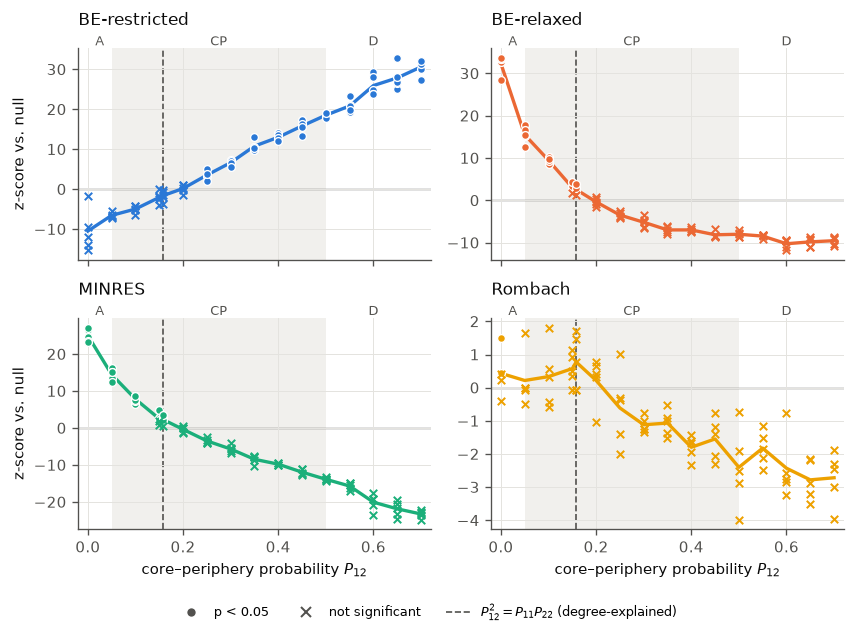

In [25]:
# Plot style shared by all figures
METHOD_ORDER = ["BE Eq. 2", "BE Eq. 4", "MINRES", "Rombach"]
METHOD_COLORS = dict(zip(METHOD_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
# Names shown in figures (as in the report)
METHOD_LABEL = {"BE Eq. 2": "BE-restricted", "BE Eq. 4": "BE-relaxed"}


def lab(name):
    """Display name of a method."""
    return METHOD_LABEL.get(name, name)

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 120,
})
FIGS = {} 

cases_df = load_csv("synthetic_cases")
null_df = load_csv("synthetic_null_summary")
p11, p22 = P11, P22
p12_deg = np.sqrt(p11 * p22)


def shade_structures(ax, label=True, xmax=1.0):
    """Grey bands for the three block structures and a dashed line at the degree-explained point."""
    ax.axvspan(p22, p11, color="#f1f0ed", zorder=0, lw=0)  # core-periphery structure
    if label:
        # A = assortative (P12 < P22), CP = core-periphery, D = disassortative (P12 > P11)
        for x, name in [(p22 / 2, "A"), ((p22 + p11) / 2, "CP"), ((p11 + xmax) / 2, "D")]:
            ax.text(x, 1.0, name, transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=7.5, color=INK_2)
    ax.axvline(p12_deg, color=INK_2, ls="--", lw=1, zorder=1)
    ax.set_xlim(-0.02, xmax + 0.02)


# One panel per method: z-score of the real score vs. the degree-preserving null, across P12.
# Filled circles: p < 0.05; crosses: not significant. (ER calibration is shown separately in 5.2.)
# Only P12 <= P12_SHOW_MAX is shown: in the densest networks BE Eq. 2's z keeps rising (to ~100)
# and would squash every other value in its panel.
P12_SHOW_MAX = 0.7
sbm = null_df[(null_df["case"] == "SBM") & (null_df["p12"] <= P12_SHOW_MAX + 1e-9)]
z_hidden = null_df[(null_df["case"] == "SBM") & (null_df["p12"] > P12_SHOW_MAX + 1e-9)]["z"]
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.2), sharex=True)
for ax, name in zip(axes.flat, METHOD_ORDER):
    col = METHOD_COLORS[name]
    d = sbm[sbm["method"] == name]
    mean_z = d.groupby("p12")["z"].mean()
    shade_structures(ax, xmax=P12_SHOW_MAX)
    ax.axhline(0, color=INK_2, lw=0.8, zorder=1)
    ax.plot(mean_z.index, mean_z.values, color=col, zorder=2)
    sig = d["p"] < 0.05
    ax.scatter(d.loc[sig, "p12"], d.loc[sig, "z"], s=22, color=col, edgecolor="white", lw=0.8, zorder=3)
    ax.scatter(d.loc[~sig, "p12"], d.loc[~sig, "z"], s=20, marker="x", color=col, lw=1.2, zorder=3)
    ax.set_title(lab(name), loc="left", pad=14, color=INK)
for ax in axes[1]:
    ax.set_xlabel(r"core–periphery probability $P_{12}$")
for ax in axes[:, 0]:
    ax.set_ylabel("z-score vs. null")

# Shared legend for marker meaning
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", color=INK_2, markeredgecolor="white", label="p < 0.05"),
           Line2D([], [], marker="x", ls="", color=INK_2, markeredgewidth=1.2, label="not significant"),
           Line2D([], [], ls="--", color=INK_2, lw=1, label=r"$P_{12}^2 = P_{11}P_{22}$ (degree-explained)")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=7.5, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.04, 1, 1))
FIGS["synthetic_significance"] = fig
plt.show()

### 5.2. Synthetic: SBM block structures

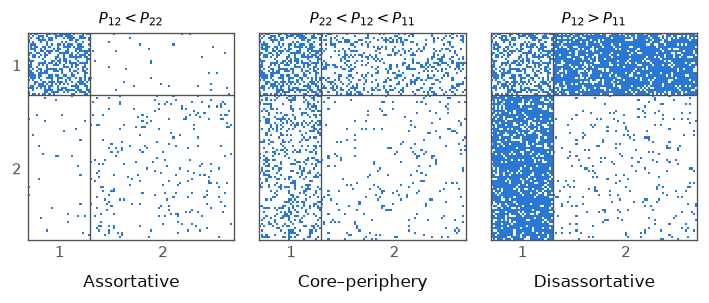

In [26]:
# Three example SBMs, one per block structure (P11, P22 fixed; only P12 changes).
# Adjacency matrices sorted by block (block 1 first).
EXAMPLES = [("Assortative", r"$P_{12} < P_{22}$", 0.02),
            ("Core–periphery", r"$P_{22} < P_{12} < P_{11}$", 0.25),
            ("Disassortative", r"$P_{12} > P_{11}$", 0.8)]
from matplotlib.colors import ListedColormap
n_core = SIZES[0]

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.8), gridspec_kw={"wspace": 0.12})
for j, (name, rule, p12) in enumerate(EXAMPLES):
    ax = axes[j]
    G, planted = make_sbm(p12, SEED)
    A = adjacency(G)
    ax.imshow(A, cmap=ListedColormap(["white", "#2a78d6"]), interpolation="none")
    ax.axhline(n_core - 0.5, color=INK_2, lw=0.8)
    ax.axvline(n_core - 0.5, color=INK_2, lw=0.8)
    ax.set_xticks([n_core / 2, n_core + SIZES[1] / 2], ["1", "2"])
    ax.set_yticks([n_core / 2, n_core + SIZES[1] / 2], ["1", "2"] if j == 0 else [])
    ax.tick_params(length=0)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(True)
        s.set_color(INK_2)
    ax.set_title(rule, fontsize=9)
    ax.set_xlabel(name, fontsize=10, labelpad=8)

FIGS["synthetic_sbm_structures"] = fig
plt.show()


### 5.3. Synthetic: null test calibration on ER networks

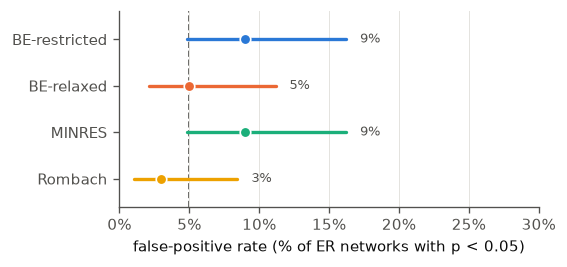

In [27]:
er_df = load_csv("synthetic_null_summary")
er_df = er_df[er_df["case"] == "ER"]


def wilson_ci(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion k / n."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


# Calibration check: on ER networks (no structure), p < 0.05 should happen ~5% of the time.
# Dot = false-positive rate per method, bar = 95% Wilson interval, dashed line = nominal 5%.
fig, ax = plt.subplots(figsize=(4.8, 2.3))
for i, name in enumerate(METHOD_ORDER):
    d = er_df[er_df["method"] == name]
    k, n = int((d["p"] < 0.05).sum()), len(d)
    lo, hi = wilson_ci(k, n)
    y = len(METHOD_ORDER) - 1 - i  # first method at the top
    ax.plot([lo, hi], [y, y], color=METHOD_COLORS[name], lw=2, solid_capstyle="round", zorder=2)
    ax.scatter([k / n], [y], s=40, color=METHOD_COLORS[name], edgecolor="white", lw=1, zorder=3)
    ax.text(hi + 0.01, y, f"{k / n:.0%}", va="center", fontsize=7.5, color=INK_2)
ax.axvline(0.05, color=INK_2, ls="--", lw=1, zorder=1)
ax.set_yticks(range(len(METHOD_ORDER)), [lab(m) for m in METHOD_ORDER[::-1]])
ax.set_xlim(0, max(0.3, ax.get_xlim()[1]))
from matplotlib.ticker import PercentFormatter
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))  # show rates as percentages
ax.set_ylim(-0.6, len(METHOD_ORDER) - 0.4)
ax.grid(axis="y", visible=False)
ax.set_xlabel("false-positive rate (% of ER networks with p < 0.05)")
fig.tight_layout()
FIGS["synthetic_er_calibration"] = fig
plt.show()

### 5.4. Synthetic: core–periphery split accuracy

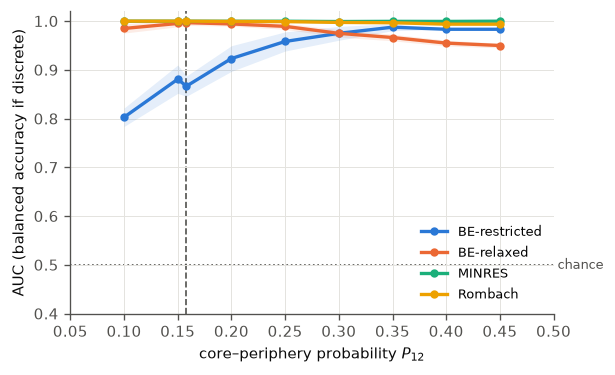

In [28]:
rec = load_csv("synthetic_recovery")

# Split accuracy on core-periphery networks (P22 < P12 < P11):
# AUC vs. the planted core (balanced accuracy for discrete methods), mean over seeds, band = +/- 1 sd.
rec_cp = rec.dropna(subset=["auc"])  # core-periphery networks only
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for name in METHOD_ORDER:
    g = rec_cp[rec_cp["method"] == name].groupby("p12")["auc"].agg(["mean", "std"])
    ax.plot(g.index, g["mean"], color=METHOD_COLORS[name], label=lab(name), marker="o", ms=4, zorder=3)
    ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"],
                    color=METHOD_COLORS[name], alpha=0.12, lw=0, zorder=2)

ax.axvline(p12_deg, color=INK_2, ls="--", lw=1, zorder=1)  # degree-explained point
ax.set_xlim(P22, P11)
ax.axhline(0.5, color=INK_2, lw=1, ls=":", zorder=1)
ax.text(1.0, 0.5, " chance", color=INK_2, fontsize=7.5, va="center", ha="left",
        transform=ax.get_yaxis_transform())
ax.set_ylim(0.4, 1.02)
ax.set_xlabel(r"core–periphery probability $P_{12}$")
ax.set_ylabel("AUC (balanced accuracy if discrete)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
FIGS["synthetic_recovery"] = fig
plt.show()

### 5.5. Synthetic: ROC curves

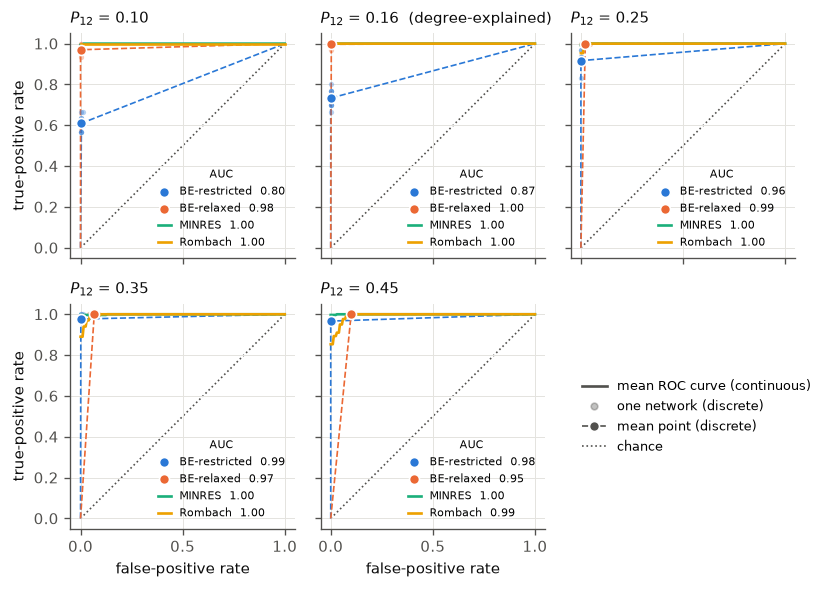

In [29]:
nodes_df = load_csv("synthetic_coreness")
rec = load_csv("synthetic_recovery")


def roc_points(score, planted):
    """ROC curve: (false-positive rate, true-positive rate) at every threshold, from (0,0) to (1,1)."""
    thresholds = np.unique(score)[::-1]  # high -> low
    tpr = [0.0] + [(score[planted == 1] >= t).mean() for t in thresholds]
    fpr = [0.0] + [(score[planted == 0] >= t).mean() for t in thresholds]
    return np.array(fpr), np.array(tpr)


# ROC curves on the core-periphery networks (P22 < P12 < P11), averaged over the 10 networks per P12.
# Continuous methods: full curve (mean TPR at each FPR). Discrete methods: one (FPR, TPR) point per network;
# the mean point joined to (0,0) and (1,1) encloses an area equal to the balanced accuracy.
ROC_P12 = [0.1, P12_DEG, 0.25, 0.35, 0.45]  # 5 of the core-periphery values (incl. degree-explained)
cp_p12 = [p for p in sorted(rec.dropna(subset=["auc"])["p12"].unique()) if np.isclose(ROC_P12, p).any()]
fpr_grid = np.linspace(0, 1, 201)

fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.0), sharex=True, sharey=True)
for ax, p12 in zip(axes.flat, cp_p12):
    ax.plot([0, 1], [0, 1], color=INK_2, ls=":", lw=1, zorder=1)  # chance
    sub = nodes_df[np.isclose(nodes_df["p12"], p12)]
    for name in METHOD_ORDER:
        mean_auc = rec[np.isclose(rec["p12"], p12) & (rec["method"] == name)]["auc"].mean()
        label = f"{lab(name)}  {mean_auc:.2f}"
        curves = []
        for seed, d in sub[sub["method"] == name].groupby("seed"):
            fpr, tpr = roc_points(d["coreness"].to_numpy(), d["planted"].to_numpy())
            curves.append((fpr, tpr))
        if name in DISCRETE:
            # 0/1 labels: the middle point of each ROC is the method's (FPR, TPR)
            pts = np.array([[f[1], t[1]] for f, t in curves])
            ax.scatter(pts[:, 0], pts[:, 1], s=10, color=METHOD_COLORS[name], alpha=0.35, lw=0, zorder=3)
            fx, ty = pts.mean(axis=0)
            ax.plot([0, fx, 1], [0, ty, 1], color=METHOD_COLORS[name], lw=1, ls="--", zorder=2)
            ax.scatter([fx], [ty], s=36, color=METHOD_COLORS[name], edgecolor="white", lw=1, zorder=4, label=label)
        else:
            mean_tpr = np.mean([np.interp(fpr_grid, f, np.maximum.accumulate(t)) for f, t in curves], axis=0)
            ax.plot(fpr_grid, mean_tpr, color=METHOD_COLORS[name], lw=1.6, zorder=3, label=label)
    ax.set_title(f"$P_{{12}}$ = {p12:.2f}" + ("  (degree-explained)" if np.isclose(p12, P12_DEG) else ""),
                 loc="left", fontsize=9, color=INK)
    ax.legend(loc="lower right", fontsize=6.5, handlelength=1.2, title="AUC", title_fontsize=6.5)
    ax.set_aspect("equal")
for ax in axes[1]:
    ax.set_xlabel("false-positive rate")
for ax in axes[:, 0]:
    ax.set_ylabel("true-positive rate")

# Last panel: key to the line/marker styles (AUC values are in each panel's legend)
from matplotlib.lines import Line2D
key = axes.flat[-1]
key.axis("off")
key.legend(handles=[Line2D([], [], color=INK_2, lw=1.6, label="mean ROC curve (continuous)"),
                    Line2D([], [], marker="o", ls="", color=INK_2, alpha=0.35, markersize=4, label="one network (discrete)"),
                    Line2D([], [], marker="o", ls="--", lw=1, color=INK_2, markeredgecolor="white", markersize=6,
                           label="mean point (discrete)"),
                    Line2D([], [], ls=":", lw=1, color=INK_2, label="chance")],
           loc="center left", fontsize=7.5)

fig.tight_layout()
FIGS["synthetic_roc"] = fig
plt.show()

### 5.6. Synthetic: method agreement

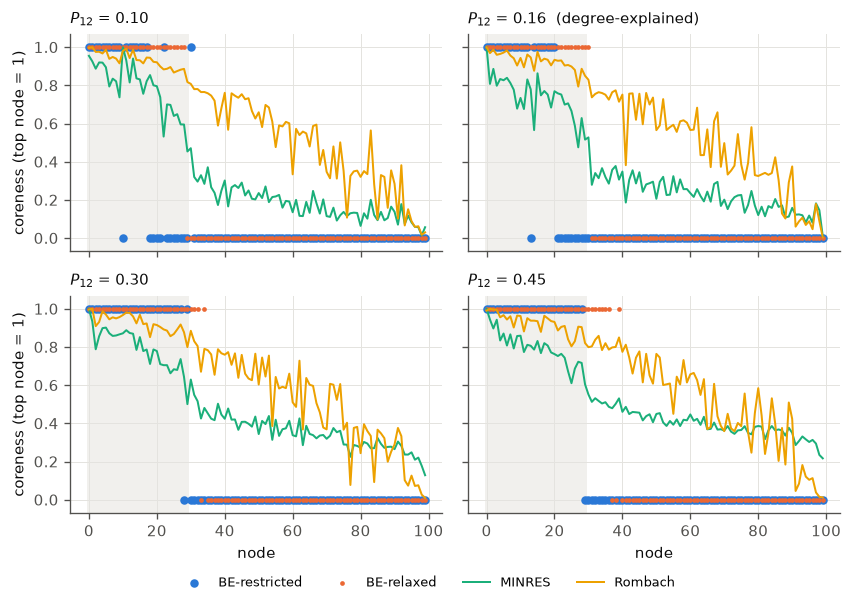

In [30]:
nodes_df = load_csv("synthetic_coreness")

# Node-level agreement: one panel per P12, all methods together.
# x = node, y = coreness scaled to [0, 1]. Continuous methods: lines; discrete methods: points at 0 or 1.
# Nodes: planted core first (shaded), then periphery, each sorted by degree (high -> low),
# using the same order for every method so the lines are comparable.
SHOW_P12 = [0.1, P12_DEG, 0.3, 0.45]  # core-periphery networks only (P22 < P12 < P11), across the range
SHOW_SEED = SEED                    # one network per P12
# Discrete points often coincide, so BE Eq. 2 is drawn as larger points underneath BE Eq. 4
POINT_SIZE = {"BE Eq. 2": 26, "BE Eq. 4": 8}

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.0), sharex=True, sharey=True)
for ax, p12 in zip(axes.flat, SHOW_P12):
    net = nodes_df[np.isclose(nodes_df["p12"], p12) & (nodes_df["seed"] == SHOW_SEED)]
    # Common node order, taken from the node attributes (same for every method)
    order = (net[net["method"] == METHOD_ORDER[0]]
             .sort_values(["planted", "degree"], ascending=False)["node"].tolist())
    ax.axvspan(-0.5, net[net["method"] == METHOD_ORDER[0]]["planted"].sum() - 0.5,
               color="#f1f0ed", lw=0, zorder=0)  # planted core
    for name in METHOD_ORDER:
        d = net[net["method"] == name].set_index("node").loc[order]
        if name in DISCRETE:
            ax.scatter(np.arange(len(d)), d["coreness"], s=POINT_SIZE[name], color=METHOD_COLORS[name],
                       lw=0, label=lab(name), zorder=3 if name == "BE Eq. 4" else 2)
        else:
            ax.plot(np.arange(len(d)), d["coreness"], color=METHOD_COLORS[name], lw=1.2, label=lab(name), zorder=4)
    ax.set_ylim(-0.07, 1.07)
    ax.set_title(f"$P_{{12}}$ = {p12:.2f}" + ("  (degree-explained)" if np.isclose(p12, P12_DEG) else ""),
                 loc="left", fontsize=9, color=INK)
for ax in axes[1]:
    ax.set_xlabel("node")
for ax in axes[:, 0]:
    ax.set_ylabel("coreness (top node = 1)")

h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.03, 1, 1))
FIGS["synthetic_coreness_by_node"] = fig
plt.show()

### 5.7. Empirical: ROC, large hubs vs. each other FAA category

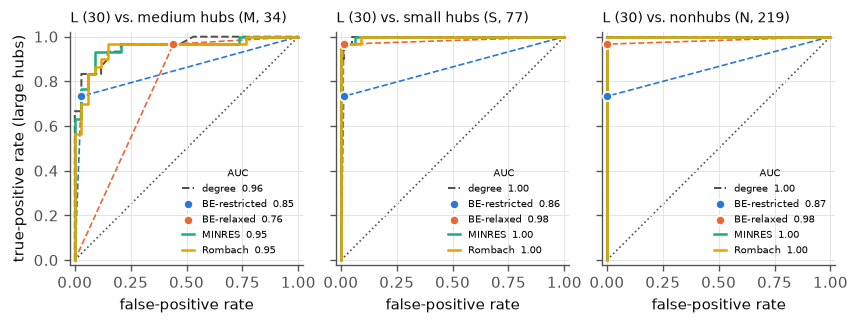

In [31]:
emp_nodes_df = load_csv("empirical_coreness")
emp_auc_df = load_csv("empirical_auc")

# ROC curves: large hubs (L) as positives vs. one other FAA category as negatives per panel.
# Continuous methods: curves; discrete methods: one point (dashed lines enclose the balanced accuracy);
# grey dashed: plain degree ranking as a baseline. Uses roc_points() from 5.4.
NEG_CATS = ["M", "S", "N"]
NEG_NAME = {"M": "medium hubs", "S": "small hubs", "N": "nonhubs"}

fig, axes = plt.subplots(1, 3, figsize=(7.2, 3.1), sharey=True)
for ax, neg in zip(axes, NEG_CATS):
    pair = emp_nodes_df[emp_nodes_df["hub"].isin(["L", neg])]
    y = (pair["hub"] == "L").astype(int).to_numpy()
    aucs = emp_auc_df[emp_auc_df["negatives"] == neg].set_index("ranking")["auc"]
    ax.plot([0, 1], [0, 1], color=INK_2, ls=":", lw=1, zorder=1)  # chance
    fpr, tpr = roc_points(pair["degree"].to_numpy(), y)
    ax.plot(fpr, tpr, color=INK_2, ls="--", lw=1.2, zorder=2, label=f"degree  {aucs['degree']:.2f}")
    for name in METHOD_ORDER:
        fpr, tpr = roc_points(pair[name].to_numpy(), y)
        label = f"{lab(name)}  {aucs[name]:.2f}"
        if name in DISCRETE:
            ax.plot(fpr, tpr, color=METHOD_COLORS[name], lw=1, ls="--", zorder=3)
            ax.scatter([fpr[1]], [tpr[1]], s=30, color=METHOD_COLORS[name], edgecolor="white", lw=1, zorder=5, label=label)
        else:
            ax.plot(fpr, tpr, color=METHOD_COLORS[name], lw=1.5, zorder=4, label=label)
    ax.set_aspect("equal")
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(f"L ({y.sum()}) vs. {NEG_NAME[neg]} ({neg}, {len(y) - y.sum()})", loc="left", fontsize=8.5, color=INK)
    ax.set_xlabel(f"false-positive rate")
    ax.legend(loc="lower right", fontsize=6, title="AUC", title_fontsize=6, handlelength=1.2)
axes[0].set_ylabel("true-positive rate (large hubs)")
fig.tight_layout()
FIGS["empirical_roc"] = fig
plt.show()

### 5.8. Empirical: coreness by FAA hub category

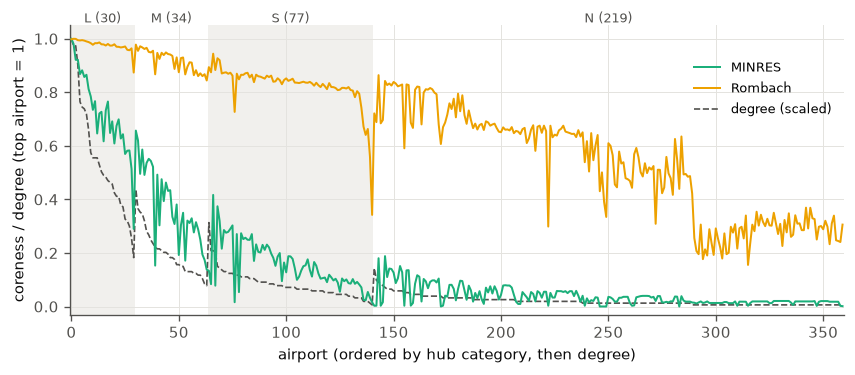

In [32]:
emp_nodes_df = load_csv("empirical_coreness")

# Coreness of the continuous methods (and degree, for comparison) along airports ordered by
# FAA hub category (L -> M -> S -> N),
# and by degree (high -> low) within each category. Nonprimary and unlisted airports are left out.
HUB_ORDER = ["L", "M", "S", "N"]
HUB_NAMES = {"L": "large", "M": "medium", "S": "small", "N": "nonhub"}
d = emp_nodes_df[emp_nodes_df["hub"].isin(HUB_ORDER)].copy()
d["hub_rank"] = d["hub"].map({h: i for i, h in enumerate(HUB_ORDER)})
d = d.sort_values(["hub_rank", "degree"], ascending=[True, False]).reset_index(drop=True)
x = np.arange(len(d))

fig, ax = plt.subplots(figsize=(7.2, 3.2))
# Category bands: alternate light shading, with the category name and count on top
start = 0
for i, hub in enumerate(HUB_ORDER):
    n = (d["hub"] == hub).sum()
    if i % 2 == 0:
        ax.axvspan(start - 0.5, start + n - 0.5, color="#f1f0ed", lw=0, zorder=0)
    ax.text(start + n / 2 - 0.5, 1.0, f"{hub} ({n})", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=7.5, color=INK_2)
    start += n
for name in [m for m in METHOD_ORDER if m not in DISCRETE]:
    ax.plot(x, d[name], color=METHOD_COLORS[name], lw=1.2, label=lab(name), zorder=3)
# Degree of each airport, scaled the same way (top airport = 1) so it shares the axis
ax.plot(x, d["degree"] / emp_nodes_df["degree"].max(), color=INK_2, lw=1, ls="--", label="degree (scaled)", zorder=2)

ax.set_xlim(-0.5, len(d) - 0.5)
ax.set_ylim(-0.03, 1.05)
ax.set_xlabel("airport (ordered by hub category, then degree)")
ax.set_ylabel("coreness / degree (top airport = 1)")
ax.legend(loc="upper right", fontsize=8, bbox_to_anchor=(1.0, 0.92))
fig.tight_layout()
FIGS["empirical_coreness_by_hub"] = fig
plt.show()

### 5.9. Empirical: hub composition of discrete cores

hub,L,M,S,N,nonprimary,unlisted,core_size
BE Eq. 2,22,1,1,0,0,0,24
BE Eq. 4,29,15,1,0,0,0,45


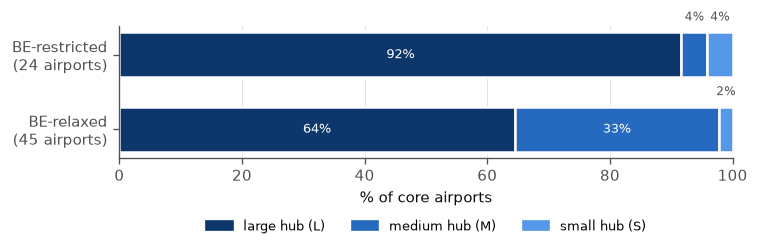

In [33]:
emp_nodes_df = load_csv("empirical_coreness")

# Hub composition of each discrete method's core: % of core airports in each FAA category.
# Ordered categories -> one blue ramp (large hub = darkest); airports without a hub category in grey.
CATS = ["L", "M", "S", "N", "nonprimary", "unlisted"]
CAT_LABEL = {"L": "large hub (L)", "M": "medium hub (M)", "S": "small hub (S)", "N": "nonhub (N)",
             "nonprimary": "nonprimary", "unlisted": "unlisted"}
CAT_COLOR = {"L": "#0d366b", "M": "#256abf", "S": "#5598e7", "N": "#9ec5f4",
             "nonprimary": "#c3c2b7", "unlisted": "#e4e3df"}
disc = [m for m in METHOD_ORDER if m in DISCRETE]
comp = pd.DataFrame({m: emp_nodes_df.loc[emp_nodes_df[m] == 1, "hub"].value_counts().reindex(CATS, fill_value=0)
                     for m in disc}).T  # rows: methods, columns: categories (counts)
pct = 100 * comp.div(comp.sum(axis=1), axis=0)
display(comp.assign(core_size=comp.sum(axis=1)))

fig, ax = plt.subplots(figsize=(6.4, 2.5))
ax.set_axisbelow(True)  # grid lines behind the bars
for i, m in enumerate(disc):
    left = 0
    y = len(disc) - 1 - i  # first method on top
    for cat in CATS:
        w = pct.loc[m, cat]
        if w == 0:
            continue
        ax.barh(y, w, left=left, height=0.6, color=CAT_COLOR[cat], edgecolor="white", lw=1.5)
        if w >= 6:  # label segments that are wide enough
            ax.text(left + w / 2, y, f"{w:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if cat in ("L", "M") else INK)
        else:       # narrow segments: label just above the bar
            ax.text(left + w / 2, y + 0.42, f"{w:.0f}%", ha="center", va="bottom", fontsize=7, color=INK_2)
        left += w
ax.set_yticks(range(len(disc)), [f"{lab(m)}\n({int(comp.loc[m].sum())} airports)" for m in disc[::-1]])
ax.set_xlim(0, 100)
ax.set_xlabel("% of core airports")
ax.grid(axis="y", visible=False)
# Legend: only categories that occur in at least one core
present = [c for c in CATS if comp[c].sum() > 0]
handles = [plt.Rectangle((0, 0), 1, 1, color=CAT_COLOR[c]) for c in present]
ax.legend(handles, [CAT_LABEL[c] for c in present], loc="upper center", bbox_to_anchor=(0.5, -0.38),
          ncol=len(present), fontsize=8)
fig.tight_layout()
FIGS["empirical_core_composition"] = fig
plt.show()

### 5.10. Empirical: null distributions with real score

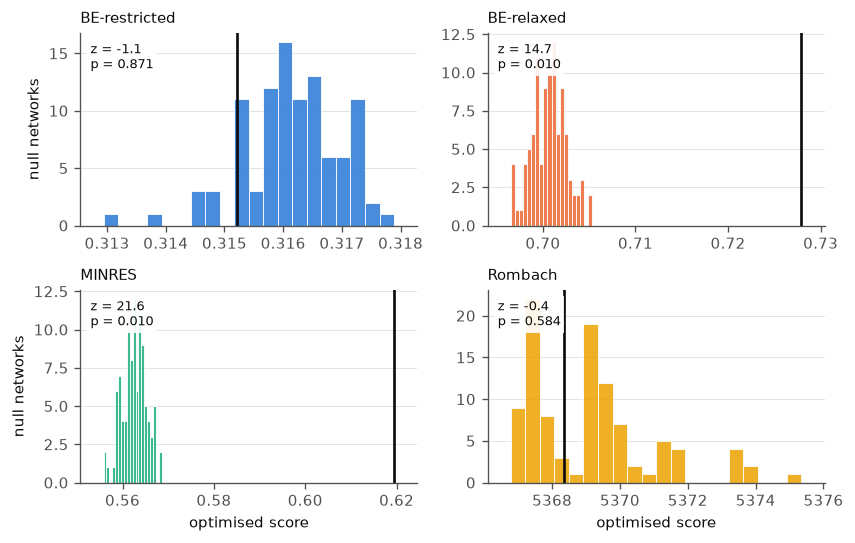

In [34]:
emp_null_df = load_csv("empirical_null_summary").set_index("method")
emp_raw_df = load_csv("empirical_null_raw")

# One panel per method: distribution of the optimised score on the rewired airport networks (histogram)
# and the real network's score (vertical line), with z and p.
fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.6))
for ax, name in zip(axes.flat, METHOD_ORDER):
    null_scores = emp_raw_df.loc[emp_raw_df["method"] == name, "null_score"]
    real = emp_null_df.loc[name, "real"]
    ax.hist(null_scores, bins=20, color=METHOD_COLORS[name], alpha=0.85, edgecolor="white", lw=0.6, zorder=2)
    ax.axvline(real, color=INK, lw=1.6, zorder=3)
    ax.text(0.03, 0.95, f"z = {emp_null_df.loc[name, 'z']:.1f}\np = {emp_null_df.loc[name, 'p']:.3f}",
            transform=ax.transAxes, va="top", ha="left", fontsize=7.5, color=INK, zorder=4,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9, pad=2))
    lo, hi = min(null_scores.min(), real), max(null_scores.max(), real)
    pad = 0.08 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_title(lab(name), loc="left", fontsize=9, color=INK)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("null networks")
for ax in axes[1]:
    ax.set_xlabel("optimised score")
fig.tight_layout()
FIGS["empirical_null"] = fig
plt.show()

### 5.11. Empirical: method agreement

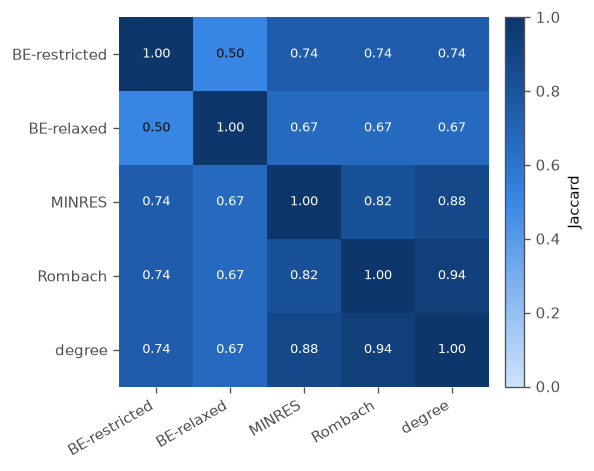

In [35]:
jac_df = load_csv("empirical_jaccard").set_index("method")

# Heatmap of the Jaccard overlap between cores (discrete methods: own core; others: top 30 airports)
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(4.8, 4.0))
im = ax.imshow(jac_df.values, cmap=blues, vmin=0, vmax=1)
labels = [lab(m) for m in jac_df.index]
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = jac_df.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.6 else INK)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Jaccard")
fig.tight_layout()
FIGS["empirical_agreement"] = fig
plt.show()

### 5.12. Empirical: core vs. periphery on the map

/var/folders/cs/fwkxzvjj20v928jjg72mlfnw0000gn/T/ipykernel_59151/2633053453.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.07, 1, 1))


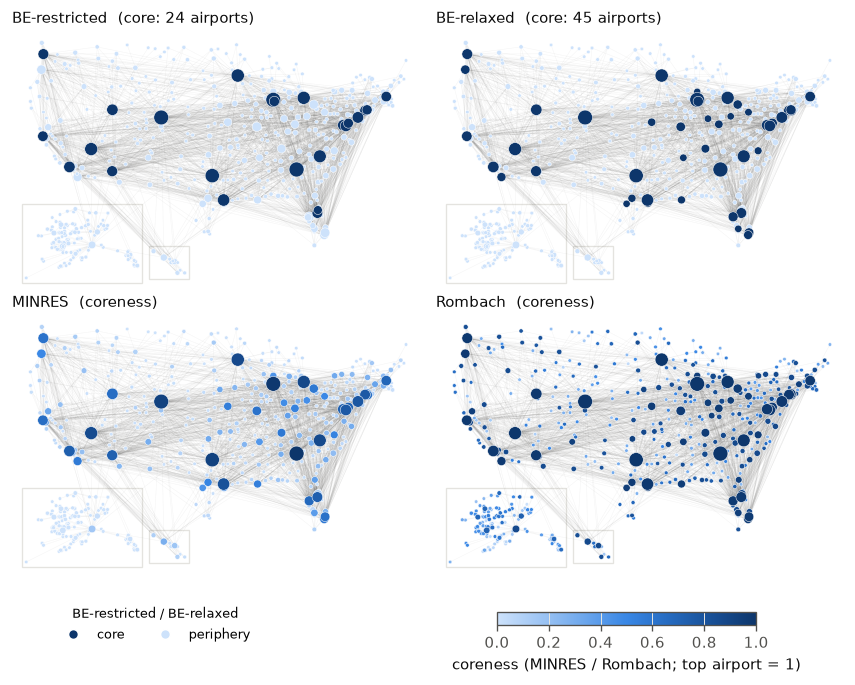

In [36]:
emp_nodes_df = load_csv("empirical_coreness").set_index("iata")
air_edges = [tuple(line.split()) for line in open(DATA_DIR / "us_airports_edgelist.txt")]


def map_xy(lon, lat):
    """Map position of an airport: mainland at its longitude/latitude; Alaska and Hawaii
    moved into insets at the bottom left (shrunk, not to scale), as on usual US maps."""
    if lon < -129 and lat > 50:                       # Alaska
        return -125 + (lon + 177) / 46 * 17, 20.5 + (lat - 51.5) / 20 * 8.5
    if lon < -150 and lat < 25:                       # Hawaii
        return -106 + (lon + 159.5) / 4.6 * 5, 21 + (lat - 19.5) / 2.6 * 3
    return lon, lat


pos = {a: map_xy(r["longitude"], r["latitude"]) for a, r in emp_nodes_df.iterrows()}
seg = np.array([[pos[a], pos[b]] for a, b in air_edges])

# Colours: one blue scale for every panel. Discrete methods use its two ends (core = dark, periphery = light);
# continuous methods use the whole scale (coreness, top airport = 1).
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
blues = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
size = 4 + 0.5 * emp_nodes_df["degree"]  # marker area grows with degree

fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4))
for ax, name in zip(axes.flat, METHOD_ORDER):
    ax.add_collection(LineCollection(seg, colors=INK_2, linewidths=0.3, alpha=0.06, zorder=1))
    d = emp_nodes_df.sort_values(name)  # draw high coreness on top
    xy = np.array([pos[a] for a in d.index])
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=d[name], cmap=blues, vmin=0, vmax=1, s=size[d.index],
                    edgecolor="white", linewidth=0.3, zorder=2)
    # Inset frames for Alaska and Hawaii
    for (x0, y0, w, h) in [(-125.5, 20, 18, 9.5), (-106.5, 20.5, 6, 4)]:
        ax.add_patch(plt.Rectangle((x0, y0), w, h, fill=False, ec=GRID, lw=0.8, zorder=0))
    ax.set_xlim(-127, -66)
    ax.set_ylim(19.5, 50)
    ax.set_aspect(1.25)
    ax.axis("off")
    title = f"{lab(name)}  (core: {int(d[name].sum())} airports)" if name in DISCRETE else f"{lab(name)}  (coreness)"
    ax.set_title(title, loc="left", fontsize=9, color=INK)

# Legend for the discrete panels and a colour bar for the continuous ones
handles = [Line2D([], [], marker="o", ls="", markersize=6, markerfacecolor=blues(1.0), markeredgecolor="white", label="core"),
           Line2D([], [], marker="o", ls="", markersize=6, markerfacecolor=blues(0.0), markeredgecolor="white", label="periphery")]
fig.legend(handles=handles, loc="lower left", ncol=2, fontsize=8, bbox_to_anchor=(0.06, -0.01), title="BE-restricted / BE-relaxed",
           title_fontsize=8)
cax = fig.add_axes([0.58, 0.035, 0.3, 0.02])
fig.colorbar(sc, cax=cax, orientation="horizontal", label="coreness (MINRES / Rombach; top airport = 1)")
fig.tight_layout(rect=(0, 0.07, 1, 1))
FIGS["empirical_core_map"] = fig
plt.show()

### 5.13. Export figures

In [37]:
# Save every figure made above as a PDF in figures/ (for Overleaf)
for name, fig in FIGS.items():
    save_fig(fig, name)

saved figures/synthetic_significance.pdf
saved figures/synthetic_sbm_structures.pdf
saved figures/synthetic_er_calibration.pdf
saved figures/synthetic_recovery.pdf


saved figures/synthetic_roc.pdf
saved figures/synthetic_coreness_by_node.pdf
saved figures/empirical_roc.pdf
saved figures/empirical_coreness_by_hub.pdf
saved figures/empirical_core_composition.pdf


saved figures/empirical_null.pdf
saved figures/empirical_agreement.pdf


saved figures/empirical_core_map.pdf


## 6. Package versions

In [38]:
# Package versions used for the results (for the report's reproducibility section)
import sys, importlib.metadata as md
print("Python", sys.version.split()[0])
for pkg in ["numpy", "scipy", "pandas", "networkx", "matplotlib", "cpnet", "numba", "joblib", "openpyxl"]:
    print(f"{pkg:12s}", md.version(pkg))

Python 3.14.7
numpy        2.5.4
scipy        1.18.1
pandas       3.1.1
networkx     3.7
matplotlib   3.11.2
cpnet        0.0.21
numba        0.68.1
joblib       1.6.0
openpyxl     3.1.5
